# Data Preprocessing Pipeline

**Purpose:** Turn the compiled raw spectra into the cleaned dataset used by every later notebook (manuscript Section 3.1, Fig. 1).

**Input:** `Raw_Raman_Dataset_2025.xlsx` (from `Raw_Dataset_Compilation.ipynb`). The wavenumber shift correction against the 520.5 cm$^{-1}$ silicon peak was already applied there.

**Output:**
- `Preprocessed_Raman_Spectra_2025.pkl` - dictionary with the spectra (360 x 1003), wavenumbers (400-1800 cm$^{-1}$), labels, replicate IDs and the preprocessing settings.
- `Paper and SI images/Figure_1.svg` - the six-panel pipeline figure.

**Pipeline order** (`SI --> CS --> BSR --> SG --> ED`), applied to every spectrum:

| Step | Manuscript | Setting |
|---|---|---|
| SI - external standard intensity normalisation | step 1 | divide by silicon peak intensity |
| CS - cosmic-ray (spike) removal | step 3 | ORPL `crfilter_single`, filter width 1, threshold 0.01 |
| BSR - baseline subtraction | step 4 | Zhang ALS fit, lambda = 100, penalty order 1 (15 iterations) |
| SG - smoothing | step 5 | Savitzky-Golay, window 15, polynomial order 2 |
| ED - edge disparity truncation | step 6 | keep 400-1800 cm$^{-1}$ |

(Step 2, wavenumber alignment to integer wavenumbers, was done in the compilation notebook.)

In [1]:
# Imports. Several are not used in this notebook (e.g. pyDOE lhs, crfilter_multi, 3D plotting); the ones that matter are
# pandas/numpy (data), BaselineRemoval (baseline), orpl (cosmic rays), scipy.signal (smoothing) and pickle (saving).
import pandas as pd
#pd.DataFrame.iteritems = pd.DataFrame.items
import numpy as np
import os
import re
import pickle

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits import mplot3d
import matplotlib.ticker as mticker
import matplotlib.transforms as transforms
import matplotlib.patches as patches
import matplotlib.cm as cm

from pyDOE import lhs

import scipy
from scipy import signal
from BaselineRemoval import BaselineRemoval
from orpl.cosmic_ray import crfilter_single
from orpl.cosmic_ray import crfilter_multi

from sklearn.preprocessing import StandardScaler, normalize

In [2]:
# Load the compiled raw dataset (360 spectra: 2 species x 2 conditions x 3 ages x 3 biological replicates x 10 technical spectra)
df_raw_data = pd.read_excel("Raw_Raman_Dataset_2025.xlsx")
df_raw_data

,Unnamed: 0,Bacteria Type,Bacteria Age,Bacteria Metabolic,Standard Intensity,Standard Area,Day of Collection,Biological Replicate,Technical Replicate,303,...,1891,1892,1893,1894,1895,1896,1897,1898,1899,1900
0,0,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,6,9690.354492,...,2632.366455,2572.550293,2592.261475,2515.951416,2568.589355,2692.611816,2536.662109,2721.135498,2578.861328,2623.322510
1,1,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,7,9479.474609,...,2451.391357,2438.163330,2479.792969,2384.254883,2373.749756,2415.390869,2402.142090,2397.125488,2378.375000,2345.882080
2,2,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,8,11910.680664,...,2829.793945,2838.581787,2784.280762,2749.163818,2755.196289,2832.594727,2852.372070,2787.035889,2826.036621,2722.212158
3,3,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,9,13743.716797,...,4033.553223,4116.628906,4122.930176,4074.359619,4102.607910,4073.227051,3994.418945,4028.159424,4105.854980,4134.136230
4,4,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,10,16047.178711,...,4499.701660,4541.730957,4506.968750,4436.524902,4475.821777,4570.029297,4384.252441,4404.340332,4517.813965,4592.874512
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,355,PP,48,C,8672.945747,50085.307680,05_09_2025,3,1,50935.437500,...,36682.957031,36539.375000,36927.898438,36787.046875,36860.187500,36461.253906,36622.203125,36980.914063,36508.482422,36374.742188
356,356,PP,48,C,8672.945747,50085.307680,05_09_2025,3,2,44410.351563,...,35311.937500,35047.410156,35345.117188,34866.480469,35224.636719,35053.199219,34961.300781,35064.320313,35033.519532,35240.261719
357,357,PP,48,C,8672.945747,50085.307680,05_09_2025,3,3,53247.000000,...,35698.566406,35842.757813,35759.328125,35483.804688,35699.386719,35577.445313,35757.437500,35492.671875,35787.466797,35561.652344
358,358,PP,48,C,8672.945747,50085.307680,05_09_2025,3,4,55195.605469,...,40573.906250,40466.746094,39931.617188,40743.410156,40378.257813,40114.515625,39776.546875,40649.351563,40110.714843,40484.136719


# General Annotated Information

In [3]:
# Pull out the label columns by position in the spreadsheet:
# col 1 species (PP = P. putida, CBG = C. glutamicum), col 2 culture age (h), col 3 condition (A = 0 mM, C = 20 mM benzoate),
# col 7 biological replicate, col 8 technical replicate
bacteria_species = np.array(df_raw_data.iloc[:,1])
culture_age = np.array(df_raw_data.iloc[:,2])
culture_condition = np.array(df_raw_data.iloc[:,3])
biological_rep = np.array(df_raw_data.iloc[:,7])
technical_rep = np.array(df_raw_data.iloc[:,8])

# Report the class balance of each label
print("Annotated Information")
ids, freq = np.unique(bacteria_species, return_counts = True)
print("The dataset contains the following species info:", ids, freq)

ids, freq = np.unique(culture_age, return_counts = True)
print("The dataset contains the following culture age info:", ids, freq)

ids, freq = np.unique(culture_condition, return_counts = True)
print("The dataset contains the following condition info:", ids, freq)

# Spectral columns start at column 9; their headers are the wavenumbers
spectral_data = np.array(df_raw_data.iloc[:,9:])
wavenumber = np.array(df_raw_data.columns[9:])
print("The training data has the following number of features:", np.shape(spectral_data)[1])
print("The training data has the following number of points:", np.shape(spectral_data)[0])

Annotated Information
The dataset contains the following species info: ['CBG' 'PP'] [180 180]
The dataset contains the following culture age info: [ 5 24 48] [120 120 120]
The dataset contains the following condition info: ['A' 'C'] [180 180]
The training data has the following number of features: 1154
The training data has the following number of points: 360


Text(0, 0.5, 'External standard peak area')

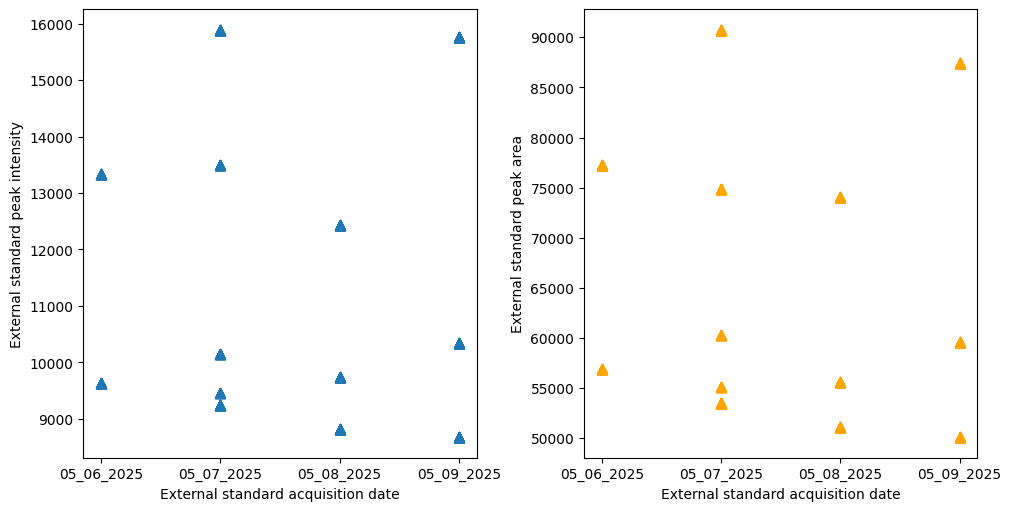

In [6]:
# External standard (silicon) records per spectrum: SI = peak intensity, SA = peak area, DT = acquisition date.
# Plotting them over time shows the instrument's intensity drift that step 1 corrects.
SI = np.array(df_raw_data.iloc[:,4])
SA = np.array(df_raw_data.iloc[:,5])
DT = np.array(df_raw_data.iloc[:,6])

fig, axs = plt.subplots(1, 2, figsize = (10, 5), sharex = True, constrained_layout = True)
ax = axs.ravel()

ax[0].scatter(DT, SI, marker = "^", s = 50)
ax[0].set_xlabel("External standard acquisition date")
ax[0].set_ylabel("External standard peak intensity")

ax[1].scatter(DT, SA, marker = "^", s = 50, color = "orange")
ax[1].set_xlabel("External standard acquisition date")
ax[1].set_ylabel("External standard peak area")

## Raw Data Visuvalization

In [7]:
# Dictionary that stores one example spectrum after each step; used later to draw the pipeline figure (Fig. 1)
transformation_dict = {}

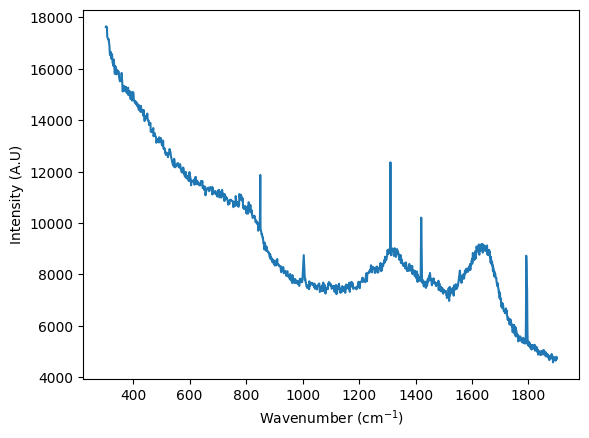

In [8]:
# Pick one spectrum (row 100) to follow through every step of the pipeline for the figure
random_ind = 100

plt.plot(wavenumber, spectral_data[random_ind, :])
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Intensity (A.U)")
# Store (wavenumber, intensity) for the 'Raw' panel
transformation_dict["Raw"] = [wavenumber, spectral_data[random_ind, :]]

## External standard peak intensity normalization

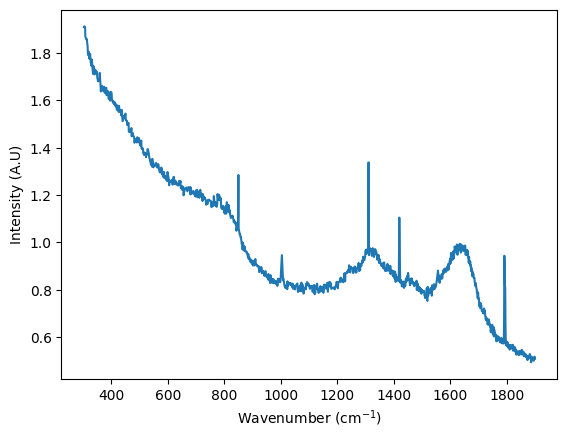

In [9]:
# Step 1 - external standard intensity normalisation: divide each spectrum by its silicon peak intensity (SI)
# to correct day-to-day and within-day intensity drift (manuscript Section 3.1, step 1).
ext_std = []

for i in range(len(spectral_data)):
    data = spectral_data[i, :]/ SI[i]
    ext_std.append(data)
    
ext_std = np.array(ext_std)
plt.plot(wavenumber, ext_std[random_ind, :])
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Intensity (A.U)")
transformation_dict["Ext peak Norm"] = [wavenumber, ext_std[random_ind, :]]

## Cosmic Ray removal

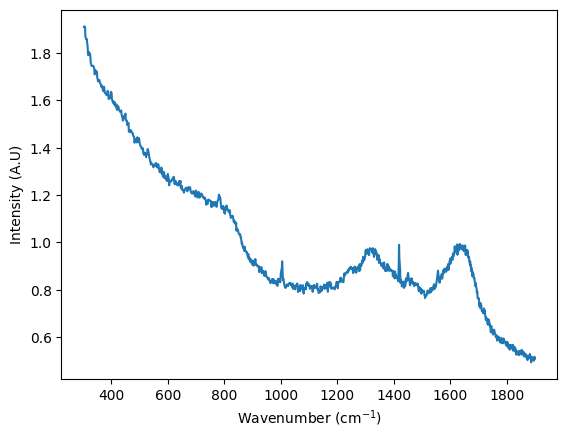

In [10]:
# Step 3 - cosmic-ray (spike) removal with ORPL's crfilter_single (second-derivative threshold algorithm).
# Parameters 1 and 0.01 are the filter width and detection threshold reported in manuscript Section 3.1.
csray_removed = []

for i in range(np.shape(ext_std)[0]):
    rd = ext_std[i,:]
    csray_removed.append(crfilter_single(rd, 1, 0.01))

csray_removed = np.array(csray_removed)

plt.plot(wavenumber, csray_removed[random_ind, :])
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Intensity (A.U)")
transformation_dict["CSray Removed"] = [wavenumber, csray_removed[random_ind, :]]

## Baseline Correction

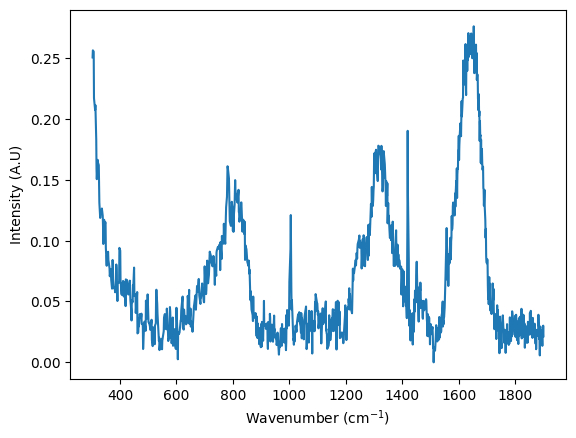

In [11]:
# Step 4 - baseline subtraction (fluorescence background) with an asymmetric least squares fit.
# ZhangFit(100, 1): lambda = 100 sets the smoothness of the fitted background, polynomial/penalty order = 1;
# the iteration count is left at the package default of 15, as reported in the manuscript.
baseline_correct = []

for i in range(len(csray_removed)):
    input_array = csray_removed[i, :]
    
    baseObj = BaselineRemoval(input_array)
    Zhangfit_output = baseObj.ZhangFit(100,1)

    # ZhangFit returns the baseline-subtracted spectrum; shift it by |minimum| so the intensities are non-negative
    xabs = min(Zhangfit_output)
    baseline = Zhangfit_output + abs(xabs)

    baseline_correct.append(baseline)

baseline_correct = np.array(baseline_correct)

plt.plot(wavenumber, baseline_correct[random_ind, :])
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Intensity (A.U)")
transformation_dict["Baseline Correction"] = [wavenumber, baseline_correct[random_ind,:]]

## Savtizky Golay Smoothing Filter

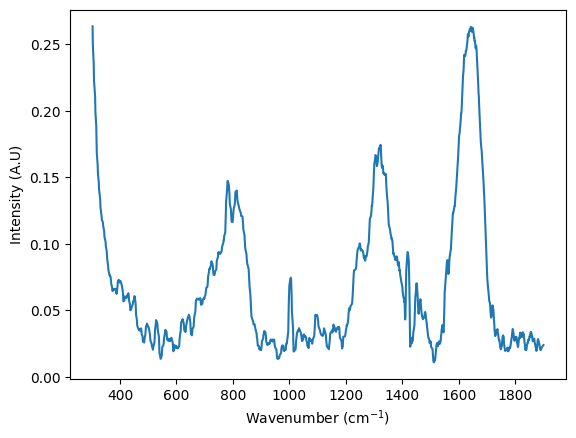

In [12]:
# Step 5 - Savitzky-Golay smoothing: window of 15 points, 2nd-order polynomial.
# Reduces high-frequency noise while preserving peak shapes.
SG_smooth = []

for i in range(len(baseline_correct)):
    data = baseline_correct[i,:]
    smooth = scipy.signal.savgol_filter(data, 15, 2)
    SG_smooth.append(smooth)

SG_smooth = np.array(SG_smooth)

plt.plot(wavenumber, SG_smooth[random_ind, :])
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Intensity (A.U)")
transformation_dict["Savtizky Golay Filter"] = [wavenumber, SG_smooth[random_ind,:]]

## Edge Disparities

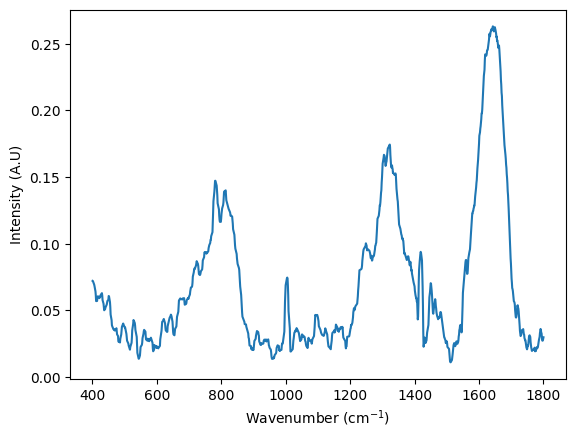

In [13]:
# Step 6 - edge disparity truncation: baseline fitting is unreliable at the ends of the spectrum, so keep only 400-1800 cm-1
# (down from 300-1900 cm-1). This leaves the 1003 wavenumbers used for all downstream analysis.
lb = 400
ub = 1800
# Indices of the first wavenumber >= 400 and the last wavenumber <= 1800 (argmax returns the first match; +1 makes the slice inclusive)
lb_ind = np.argmax(wavenumber >= lb)
ub_ind = np.argmax(wavenumber >= ub)+1
wavenumber_final = wavenumber[lb_ind:ub_ind]

edge_disparity = []
for i in range(len(SG_smooth)):
    temp = SG_smooth[i,lb_ind:ub_ind]
    edge_disparity.append(temp)

edge_disparity = np.array(edge_disparity)


plt.plot(wavenumber_final, edge_disparity[random_ind, :])
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Intensity (A.U)")
transformation_dict["Edge Disparity"] = [wavenumber_final, edge_disparity[random_ind,:]]

## Complete preprocessing pipeline visuvalization

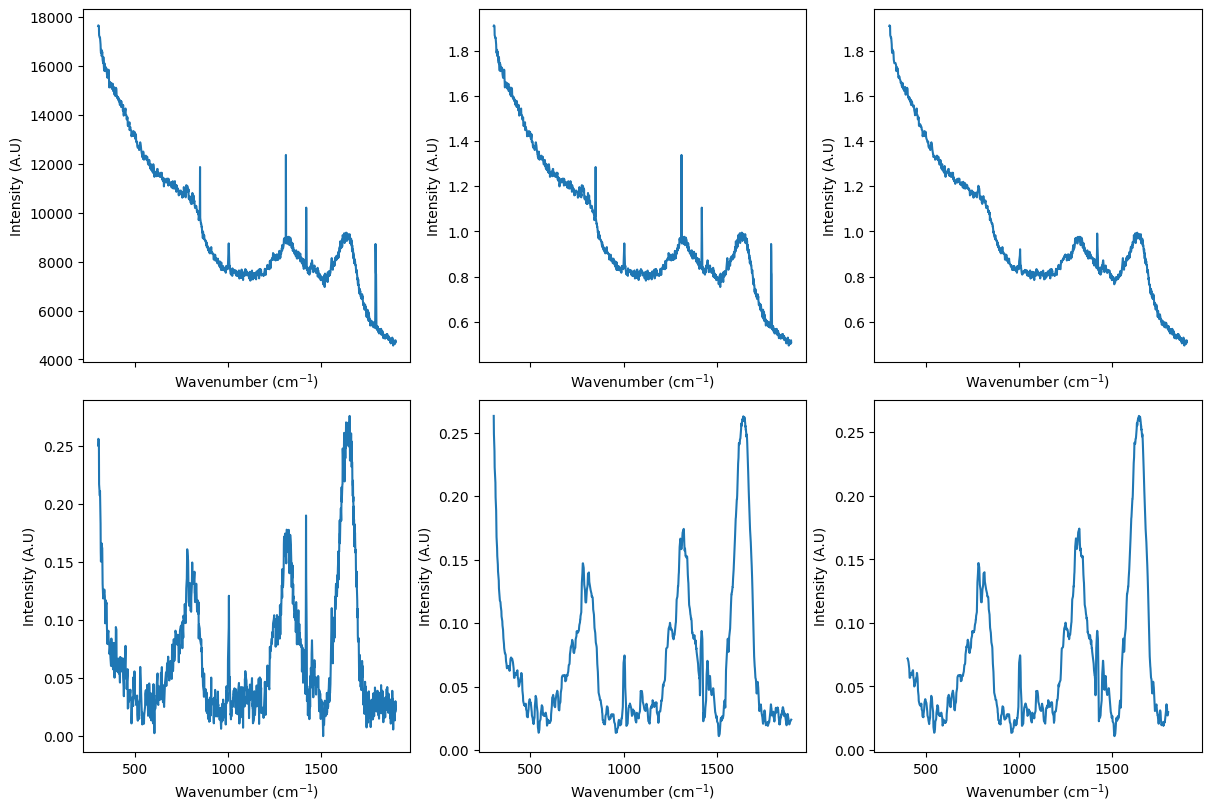

In [14]:
# Quick-look figure: one example spectrum after each of the six stages
fig, axs = plt.subplots(2, 3, figsize = (12, 8), sharex = True, constrained_layout = True)
ax = axs.ravel()
keys = list(transformation_dict.keys())

for i in range(len(keys)):
    k = keys[i]
    val = transformation_dict[k]
    ax[i].plot(val[0], val[1])
    ax[i].set_ylabel("Intensity (A.U)")
    ax[i].set_xlabel("Wavenumber (cm$^{-1}$)")

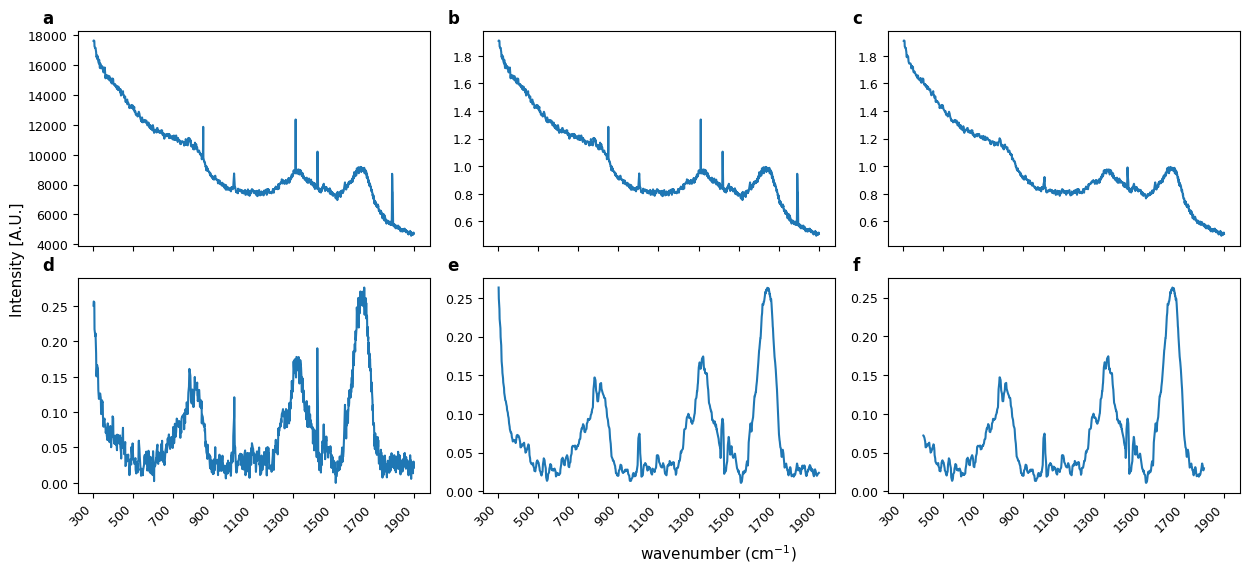

In [15]:
# Final publication version of the pipeline figure (Fig. 1 a-f): a 2 x 3 grid of the six stages stored in transformation_dict.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
# -------------------
# Styling
# -------------------
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

# --- Figure and GridSpec layout ---
fig = plt.figure(figsize=(15, 6))
gs = GridSpec(nrows=2, ncols=3, figure=fig, hspace=0.15, wspace=0.15)

axes = []
for r in range(2):
    for c in range(3):
        ax = fig.add_subplot(gs[r, c], sharex=axes[0] if axes else None)
        axes.append(ax)

# --- Plotting ---

for ax, k in zip(axes, keys):
    val = transformation_dict[k]
    ax.plot(val[0], val[1])

# --- Shared x-axis formatting ---
for ax in axes:
#    ax.set_xlim(200, 2000)
    ax.set_xticks(np.arange(300, 1901, 200))#, rotation = 45)

# Only label the bottom row's x-axis to avoid clutter
# Hide x tick labels on the top row
for ax in axes[:3]:
    plt.setp(ax.get_xticklabels(), visible=False)

# Rotate x tick labels on the bottom row
for ax in axes[3:]:
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

# Example y-labels (optional)
fig.text(0.5, 0.01, "wavenumber (cm$^{-1}$)", va="center", fontsize = 11)
fig.text(0.08, 0.5, "Intensity [A.U.]", va="center", rotation = 90, fontsize = 11)

labels = ["a", "b", "c", "d", "e", "f"]
axs = range(6)

for ax, label in zip(axs, labels):
    axes[ax].text(
        -0.1, 1.1, label,
        transform=axes[ax].transAxes,
        fontsize=PANEL_LABEL_SIZE,
        fontweight="bold",
        va="top"
    )
plt.savefig("Paper and SI images//Figure_1.svg")

## Pickle File Generation 

In [16]:
# Bundle everything the downstream notebooks need into one dictionary and pickle it.
final_processed_raman = {}

final_processed_raman["Spectra"] = edge_disparity
final_processed_raman["wavenumber"] = wavenumber_final
final_processed_raman["species label"] = bacteria_species
final_processed_raman["culture age"] = culture_age
final_processed_raman["culture condition"] = culture_condition
final_processed_raman["biological replicate"] = biological_rep
final_processed_raman["technical replicate"] = technical_rep

# Record the preprocessing settings for provenance (order and parameters of each step)
final_processed_raman["Preprocess conditions"] = {"order" : "SI --> CS --> BSR --> SG --> ED",
                                                 "CS" : [1, 0.01],
                                                 "BSR" : [100, 1],
                                                 "SG" : [15, 2],
                                                 "ED" : [400, 1800]}

# Save to disk (input for PCA_Qualitative_Analysis, the HypTune notebooks and Interpretability_Analysis)
file_name = "Preprocessed_Raman_Spectra_2025.pkl"
with open(file_name, "wb") as f:
    pickle.dump(final_processed_raman, f)

In [ ]:
# (empty cell)
